In [52]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

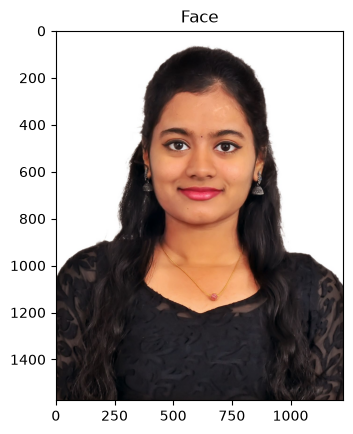

In [53]:
# Load the Face Image
faceImage = cv2.imread('photo.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [54]:
faceImage.shape

(1575, 1225, 3)

In [55]:
#resized_faceImage.shape
faceImage.shape

(1575, 1225, 3)

Text(0.5, 1.0, 'glassPNG')

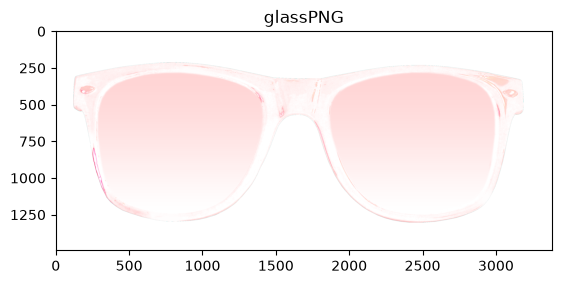

In [56]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [57]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [58]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]


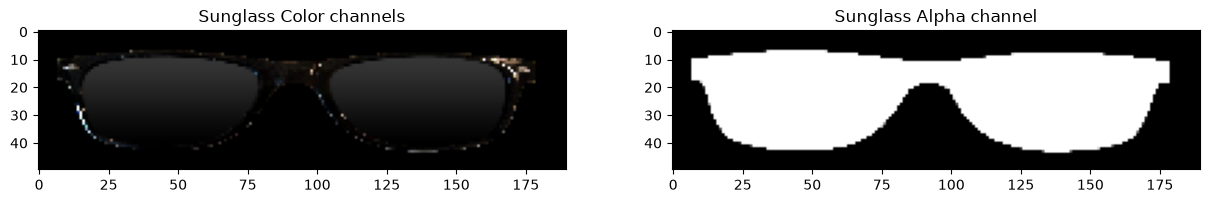

In [59]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

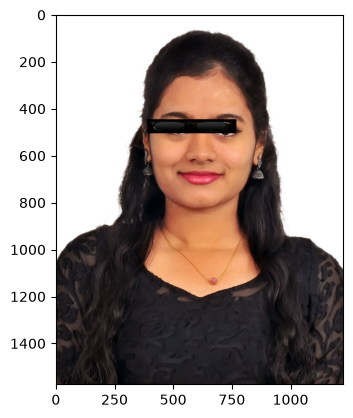

In [61]:
glassBGR = cv2.resize(glassBGR, (380, 60))
faceWithGlassesNaive = faceImage.copy()
faceWithGlassesNaive[445:505, 390:770] = glassBGR

plt.imshow(faceWithGlassesNaive[..., ::-1])

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

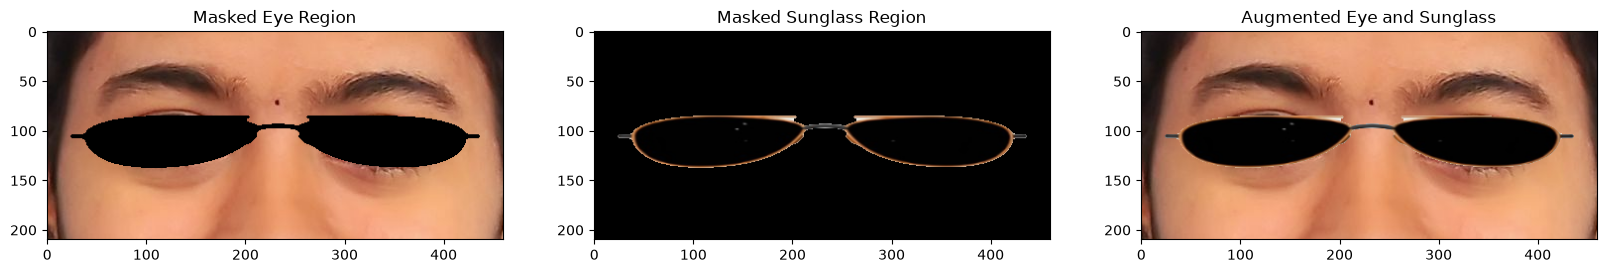

In [157]:
# Make the dimensions of the mask same as the input image.
# Since Face Image is a 3-channel image, we create a 3 channel image for the mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask/255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the correct eye region from the high-res face image (expanded bounds)
y1, y2 = 380, 590
x1, x2 = 390, 850
eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2]

# Resize the glassMask to match the eyeROI dimensions
glassMask = cv2.resize(glassMask, (eyeROI.shape[1], eyeROI.shape[0]))

# Resize glassBGR to match the eyeROI dimensions
glassBGR_resized = cv2.resize(glassBGR, (eyeROI.shape[1], eyeROI.shape[0]))

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR_resized, glassMask)

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=[20,20])
plt.subplot(131);plt.imshow(maskedEye[...,::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[...,::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[...,::-1]);plt.title("Augmented Eye and Sunglass")

Text(0.5, 1.0, 'With Sunglasses')

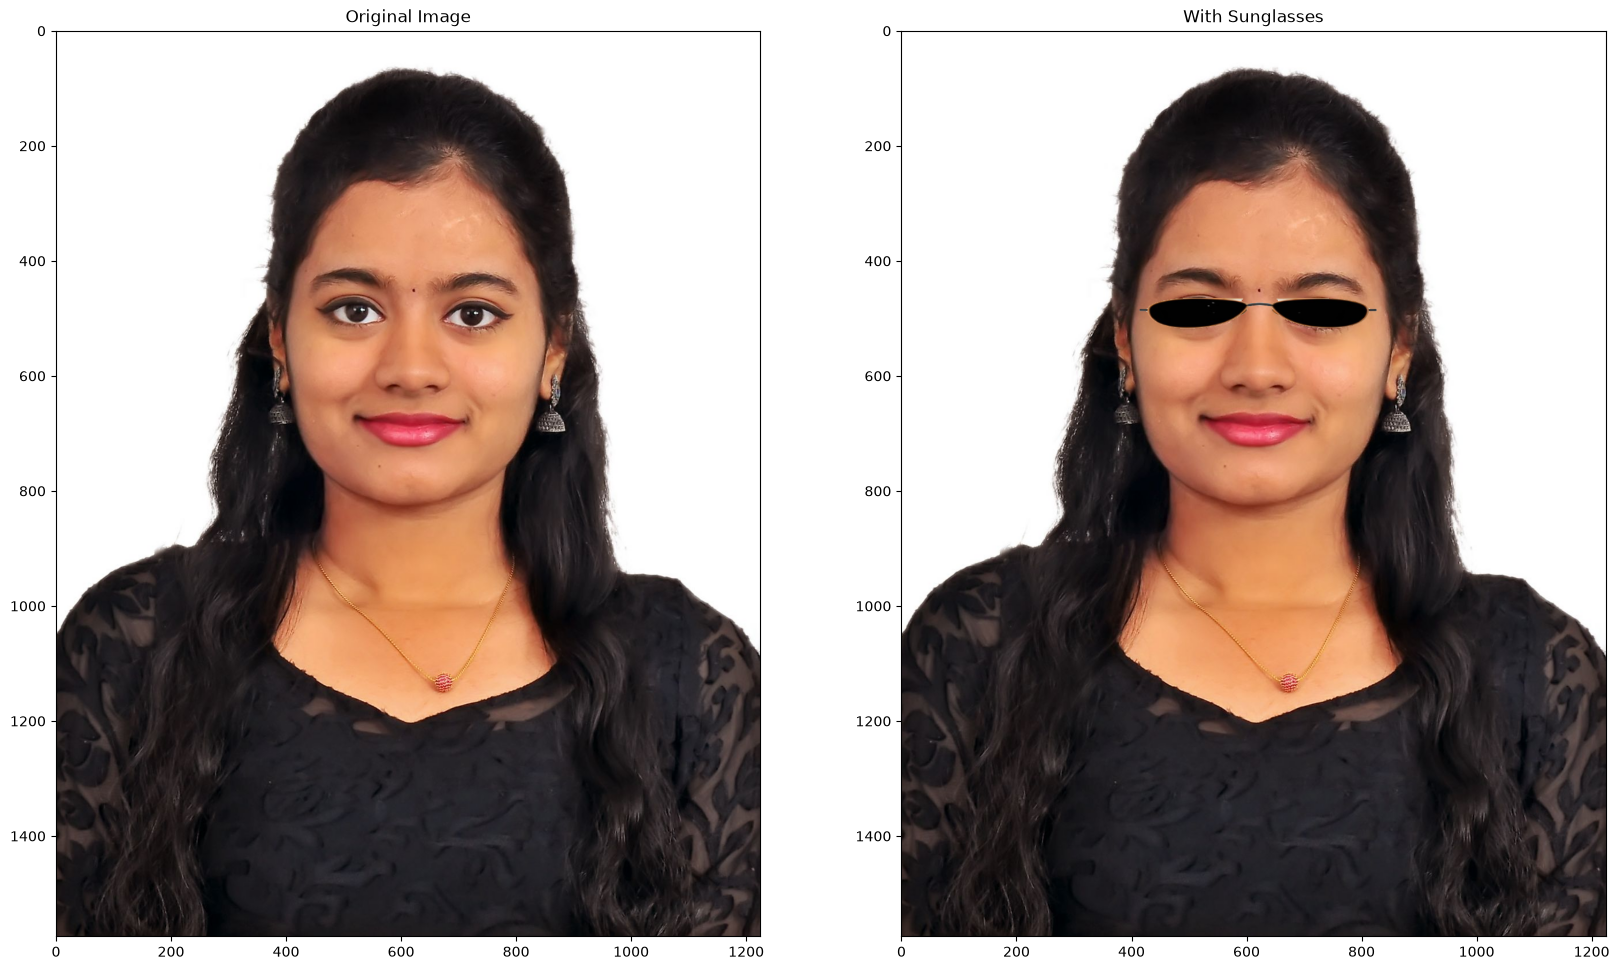

In [158]:
# Replace the eye ROI with the output from the previous section
y1, y2 = 380, 590
x1, x2 = 390, 850
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20])
plt.subplot(121);plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image")
plt.subplot(122);plt.imshow(faceWithGlassesArithmetic[:,:,::-1]);plt.title("With Sunglasses")